# Bias–Variance Trade-off in Regression

This notebook illustrates bias and variance in a setting directly relevant to regression.

Suppose the data are generated by

$$
Y=f(X)+\varepsilon,
\qquad
E[\varepsilon\mid X]=0,
\qquad
\operatorname{Var}(\varepsilon\mid X)=\sigma^2.
$$

We repeatedly collect new training datasets from the same data-generating process and fit a regression model each time.

Because the training data change, the fitted regression function

$$
\hat f_{\mathcal D}(x)
$$

also changes.

At a fixed input \(x_0\), we can therefore ask:

$$
\boxed{
\operatorname{Bias}(x_0)
=
E_{\mathcal D}[\hat f_{\mathcal D}(x_0)]-f(x_0)
}
$$

and

$$
\boxed{
\operatorname{Var}(x_0)
=
E_{\mathcal D}
\left[
\left(
\hat f_{\mathcal D}(x_0)
-
E_{\mathcal D}[\hat f_{\mathcal D}(x_0)]
\right)^2
\right].
}
$$

This gives the regression bias–variance decomposition.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(4)

## 1. True regression function

We use a nonlinear true mean function

$$
f(x)=\sin(x)+0.25x.
$$

Observed responses contain Gaussian noise:

$$
Y=f(X)+\varepsilon,
\qquad
\varepsilon\sim N(0,\sigma^2).
$$

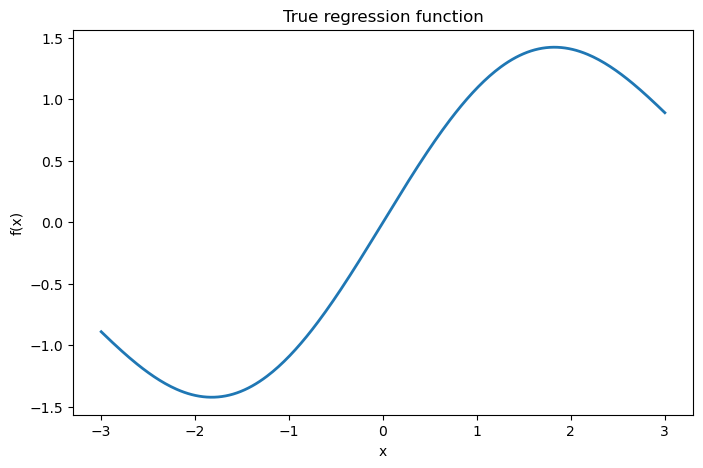

In [2]:
def f_true(x):
    return np.sin(x) + 0.25*x

sigma = 0.45

x_grid = np.linspace(-3,3,300)

plt.figure(figsize=(8,5))
plt.plot(x_grid, f_true(x_grid), linewidth=2)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("True regression function")
plt.show()

## 2. One training dataset

First look at one realization of the data.

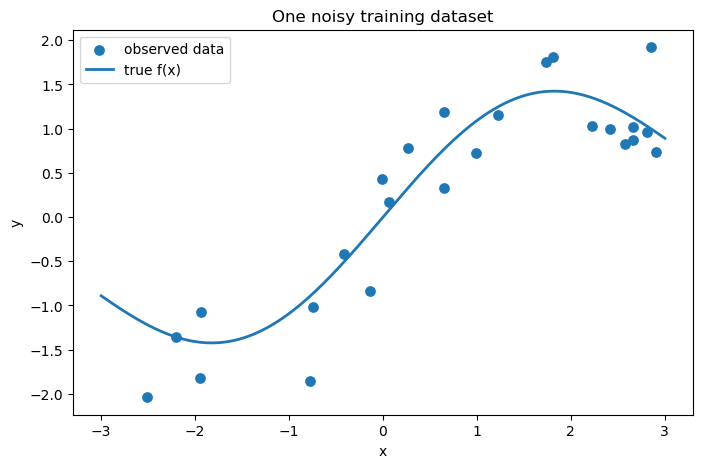

In [3]:
n = 25

x = np.sort(rng.uniform(-3,3,n))
y = f_true(x) + rng.normal(0,sigma,n)

plt.figure(figsize=(8,5))
plt.scatter(x,y,s=45,label="observed data")
plt.plot(x_grid,f_true(x_grid),linewidth=2,label="true f(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("One noisy training dataset")
plt.legend()
plt.show()

## 3. Fit models of different complexity

We compare polynomial regression with degrees

$$
d=1,\qquad d=3,\qquad d=12.
$$

These represent:

- low complexity,
- moderate complexity,
- high complexity.

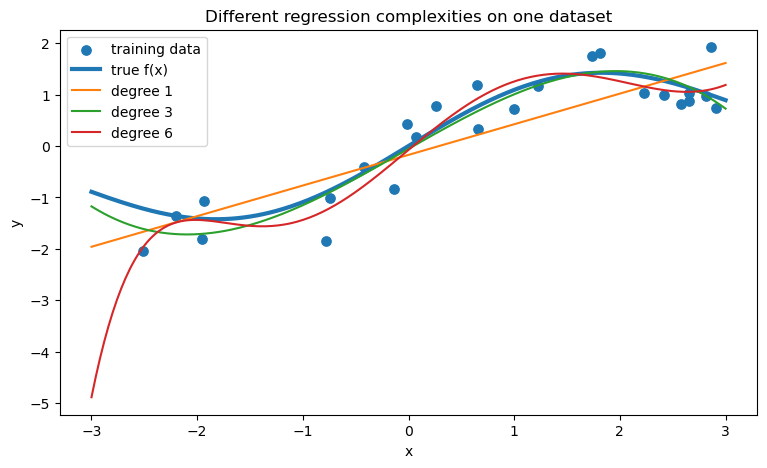

In [5]:
degrees = [1,3,6]

plt.figure(figsize=(9,5))
plt.scatter(x,y,s=45,label="training data")
plt.plot(x_grid,f_true(x_grid),linewidth=3,label="true f(x)")

for d in degrees:
    poly = PolynomialFeatures(degree=d,include_bias=False)
    X = poly.fit_transform(x.reshape(-1,1))
    Xg = poly.transform(x_grid.reshape(-1,1))

    model = LinearRegression().fit(X,y)
    plt.plot(x_grid,model.predict(Xg),label=f"degree {d}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Different regression complexities on one dataset")
plt.legend()
plt.show()

From only one dataset, it is tempting to judge the models visually.

But **bias and variance are properties across repeated datasets**.

So now we repeat the entire experiment many times.

# 4. Repeated datasets

For each repetition:

1. draw a new training dataset;
2. fit degree-1, degree-3, and degree-6 regressions;
3. evaluate the fitted functions on the same grid.

This produces many possible fitted functions

$$
\hat f_{\mathcal D}(x).
$$

In [9]:
R = 300
n = 25

predictions = {
    d: np.zeros((R,len(x_grid)))
    for d in degrees
}

for r in range(R):
    xr = np.sort(rng.uniform(-3,3,n))
    yr = f_true(xr) + rng.normal(0,sigma,n)

    for d in degrees:
        poly = PolynomialFeatures(degree=d,include_bias=False)
        Xr = poly.fit_transform(xr.reshape(-1,1))
        Xg = poly.transform(x_grid.reshape(-1,1))

        model = LinearRegression().fit(Xr,yr)
        predictions[d][r] = model.predict(Xg)

## 5. Visualize fitted functions across datasets

Each thin curve below comes from a different training dataset.

This gives a direct visual interpretation of variance:

$$
\boxed{
\text{How much does the fitted function change when the training sample changes?}
}
$$

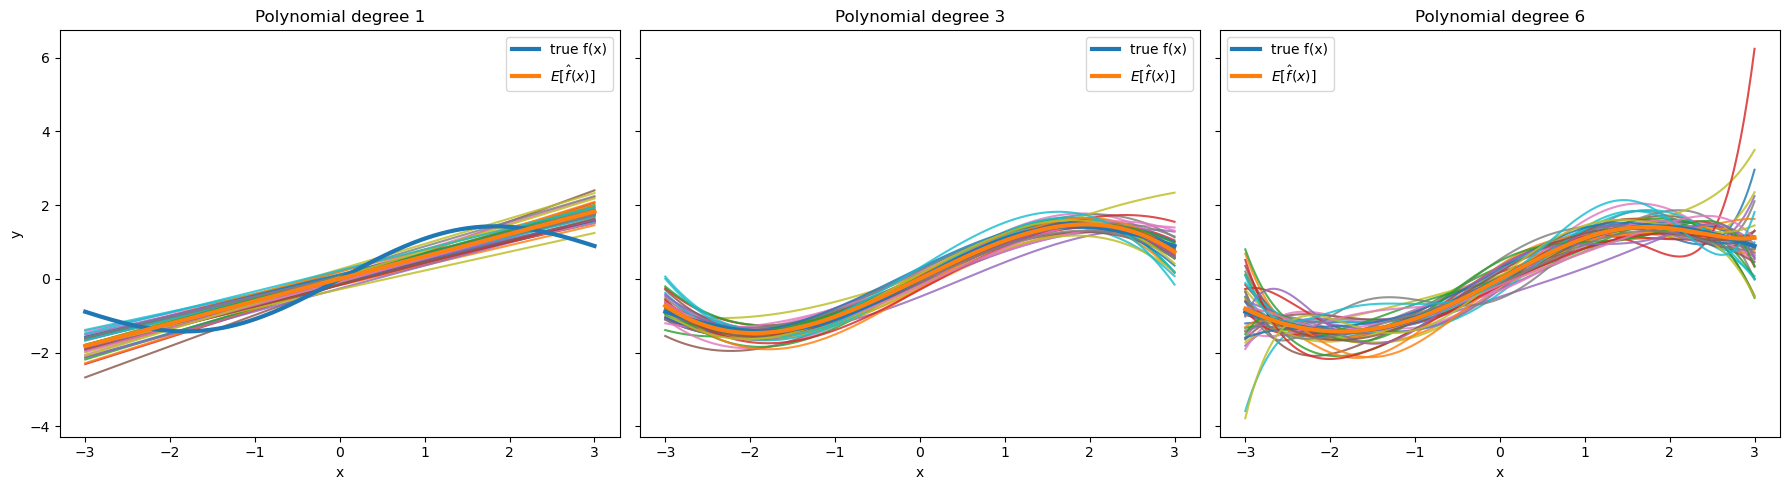

In [10]:
fig, axes = plt.subplots(1,3,figsize=(18,5),sharey=True)

for ax,d in zip(axes,degrees):
    for r in range(40):
        ax.plot(x_grid,predictions[d][r],alpha=0.82)

    ax.plot(x_grid,f_true(x_grid),linewidth=3,label="true f(x)")
    ax.plot(
        x_grid,
        predictions[d].mean(axis=0),
        linewidth=3,
        label=r"$E[\hat f(x)]$"
    )

    ax.set_title(f"Polynomial degree {d}")
    ax.set_xlabel("x")
    ax.legend()

axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

Interpretation:

### Degree 1

The fitted lines do not fluctuate wildly, but their average cannot represent the nonlinear truth well.

$$
\boxed{\text{low variance, high bias}}
$$

### Degree 3

The model is flexible enough to capture the main structure without being excessively unstable.

$$
\boxed{\text{moderate bias, moderate variance}}
$$

### Degree 12

The model can fit each individual dataset very closely, but the fitted curve changes substantially between datasets.

$$
\boxed{\text{low training bias, high variance}}
$$

# 6. Bias and variance at a single input \(x_0\)

Pick

$$
x_0=1.
$$

Each training dataset produces one prediction

$$
\hat f_{\mathcal D}(x_0).
$$

The distribution of these predictions lets us compute bias and variance directly.

In [11]:
x0 = 1.0
i0 = np.argmin(np.abs(x_grid-x0))
true0 = f_true(x_grid[i0])

rows=[]

for d in degrees:
    pred0 = predictions[d][:,i0]

    mean_pred = pred0.mean()
    bias = mean_pred-true0
    variance = pred0.var()
    mse_mean_function = np.mean((pred0-true0)**2)

    rows.append({
        "degree":d,
        "true f(x0)":true0,
        "E[fhat(x0)]":mean_pred,
        "bias":bias,
        "bias^2":bias**2,
        "variance":variance,
        "MSE around f(x0)":mse_mean_function
    })

pd.DataFrame(rows)

,degree,true f(x0),E[fhat(x0)],bias,bias^2,variance,MSE around f(x0)
0,1,1.086166,0.605972,-0.480194,0.230587,0.024285,0.254872
1,3,1.086166,1.030490,-0.055676,0.003100,0.031893,0.034993
2,6,1.086166,1.097873,0.011707,0.000137,0.058172,0.058309


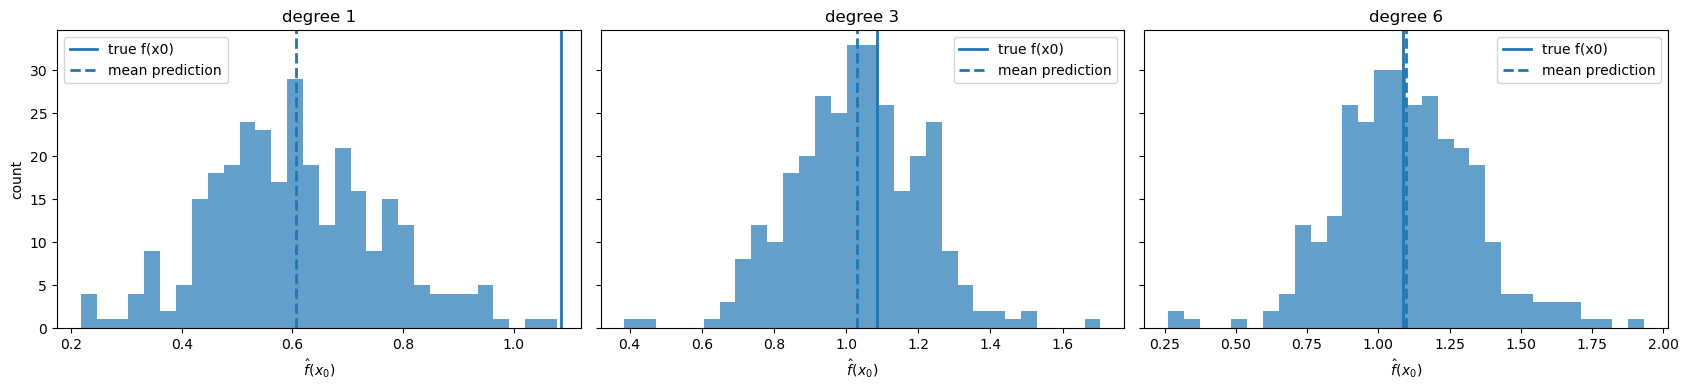

In [12]:
fig, axes = plt.subplots(1,3,figsize=(17,4),sharey=True)

for ax,d in zip(axes,degrees):
    pred0 = predictions[d][:,i0]

    ax.hist(pred0,bins=30,alpha=0.7)
    ax.axvline(true0,linewidth=2,label="true f(x0)")
    ax.axvline(pred0.mean(),linewidth=2,linestyle="--",
               label="mean prediction")

    ax.set_title(f"degree {d}")
    ax.set_xlabel(r"$\hat f(x_0)$")
    ax.legend()

axes[0].set_ylabel("count")
plt.tight_layout()
plt.show()

At a fixed input,

$$
\boxed{
E_{\mathcal D}
[
(\hat f(x_0)-f(x_0))^2
]
=
\operatorname{Bias}(x_0)^2
+
\operatorname{Var}(x_0).
}
$$

We can verify this numerically.

In [13]:
for d in degrees:
    pred0 = predictions[d][:,i0]

    bias2 = (pred0.mean()-true0)**2
    var = pred0.var()
    mse = np.mean((pred0-true0)**2)

    print(
        f"degree {d}:  "
        f"MSE={mse:.5f},  "
        f"bias^2 + variance={bias2+var:.5f}"
    )

degree 1:  MSE=0.25487,  bias^2 + variance=0.25487
degree 3:  MSE=0.03499,  bias^2 + variance=0.03499
degree 6:  MSE=0.05831,  bias^2 + variance=0.05831


# 7. Prediction error includes irreducible noise

So far we compared \(\hat f(x)\) with the true conditional mean \(f(x)\).

But a new observed response is

$$
Y_{\rm new}
=
f(x)+\varepsilon_{\rm new}.
$$

Therefore

$$
E[
(Y_{\rm new}-\hat f(x))^2
]
$$

contains one additional term:

$$
\boxed{
E[
(Y_{\rm new}-\hat f(x))^2
]
=
\sigma^2
+
\operatorname{Bias}(x)^2
+
\operatorname{Var}(x).
}
$$

The \(\sigma^2\) term is the **irreducible noise**.

In [14]:
rows=[]

for d in degrees:
    P = predictions[d]

    mean_pred = P.mean(axis=0)

    bias2_x = (mean_pred-f_true(x_grid))**2
    var_x = P.var(axis=0)

    rows.append({
        "degree":d,
        "average bias^2":bias2_x.mean(),
        "average variance":var_x.mean(),
        "noise sigma^2":sigma**2,
        "expected prediction MSE":
            bias2_x.mean()+var_x.mean()+sigma**2
    })

summary = pd.DataFrame(rows)
summary

,degree,average bias^2,average variance,noise sigma^2,expected prediction MSE
0,1,0.167573,0.035038,0.2025,0.405112
1,3,0.003079,0.043327,0.2025,0.248906
2,6,0.001185,0.630610,0.2025,0.834295


## 8. Bias–variance decomposition across model complexity

Now vary polynomial degree from 1 to 15.

For each degree, estimate average

$$
\operatorname{Bias}^2,
\qquad
\operatorname{Variance},
$$

over the input grid.

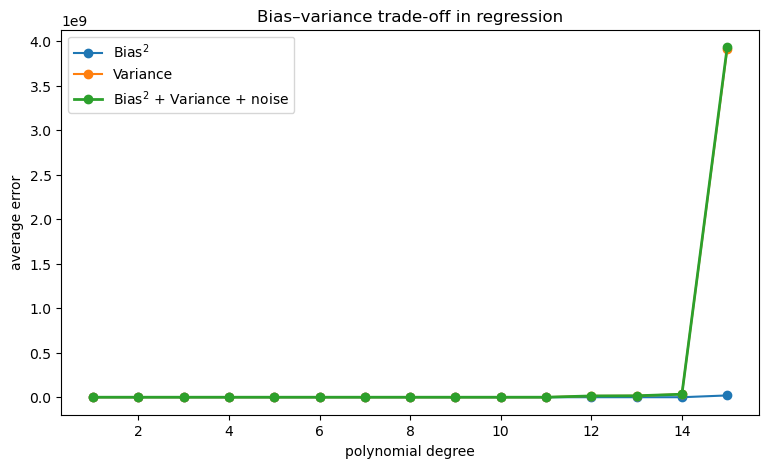

In [15]:
degree_grid = np.arange(1,16)

avg_bias2=[]
avg_var=[]
avg_total=[]

R2 = 180

for d in degree_grid:
    P = np.zeros((R2,len(x_grid)))

    for r in range(R2):
        xr = np.sort(rng.uniform(-3,3,n))
        yr = f_true(xr)+rng.normal(0,sigma,n)

        poly = PolynomialFeatures(degree=d,include_bias=False)
        Xr = poly.fit_transform(xr.reshape(-1,1))
        Xg = poly.transform(x_grid.reshape(-1,1))

        model = LinearRegression().fit(Xr,yr)
        P[r] = model.predict(Xg)

    mean_pred = P.mean(axis=0)
    bias2 = np.mean((mean_pred-f_true(x_grid))**2)
    var = np.mean(P.var(axis=0))

    avg_bias2.append(bias2)
    avg_var.append(var)
    avg_total.append(bias2+var+sigma**2)

plt.figure(figsize=(9,5))
plt.plot(degree_grid,avg_bias2,marker="o",label=r"Bias$^2$")
plt.plot(degree_grid,avg_var,marker="o",label="Variance")
plt.plot(degree_grid,avg_total,marker="o",linewidth=2,
         label=r"Bias$^2$ + Variance + noise")
plt.xlabel("polynomial degree")
plt.ylabel("average error")
plt.title("Bias–variance trade-off in regression")
plt.legend()
plt.show()

This is the regression version of the bias–variance trade-off:

\[
\boxed{
\text{low complexity}
\Rightarrow
\text{high bias, low variance}
}
\]

\[
\boxed{
\text{high complexity}
\Rightarrow
\text{low bias, high variance}.
}
\]

Good generalization requires balancing the two.

# 9. Connection to underfitting and overfitting

### Underfitting

A model is too rigid to represent the true regression function.

Typical signature:

\[
\boxed{
\text{high training error}
\quad+\quad
\text{high test error}
}
\]

and often high bias.

### Overfitting

A model reacts strongly to sample-specific noise.

Typical signature:

\[
\boxed{
\text{very low training error}
\quad+\quad
\text{larger test error}
}
\]

and often high variance.

So the concepts from today's lecture fit together:

\[
\boxed{
\text{model complexity}
\longrightarrow
\text{bias--variance trade-off}
\longrightarrow
\text{under/overfitting}
\longrightarrow
\text{generalization error}.
}
\]

# Take-home message

For regression, the estimator is not just a coefficient:

\[
\hat f_{\mathcal D}(x)
\]

is itself an estimator of the true regression function

\[
f(x)=E[Y\mid X=x].
\]

Because the fitted function depends on the training sample,

\[
\hat f_{\mathcal D}(x)
\]

changes from dataset to dataset.

At any fixed \(x\),

\[
\boxed{
E_{\mathcal D}
[
(\hat f(x)-f(x))^2
]
=
\operatorname{Bias}(x)^2
+
\operatorname{Var}(x).
}
\]

For prediction of a new noisy observation,

\[
\boxed{
E[
(Y_{\rm new}-\hat f(x))^2
]
=
\sigma^2
+
\operatorname{Bias}(x)^2
+
\operatorname{Var}(x).
}
\]

The noise term \(\sigma^2\) cannot be eliminated by choosing a better regression model.